# Titanic Survival Prediction 

This notebook provides a clean, reproducible, and leakage-free machine learning pipeline for predicting Titanic survival:
1. **Exploratory Data Analysis (EDA):** Inspect data distributions, missing values, class imbalance, and survival rates across key features.
2. **Feature Engineering:** Extract and group passenger `Title`, and create ordered `AgeGroup` bins.
3. **Leakage-Free Preprocessing Pipeline:** Separate numerical, ordinal, and nominal features inside a `ColumnTransformer` fit strictly within cross-validation folds.
4. **Model Comparison & Tuning:** Compare Logistic Regression, Random Forest, and XGBoost using Stratified 5-Fold Cross-Validation across Accuracy, Precision, Recall, and F1.
5. **Final Test Evaluation:** Evaluate the selected model once on the held-out test set with a classification report and normalized confusion matrix.

## 1. Setup & Data Inspection

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")

In [28]:
titanic = pd.read_csv("train.csv")
titanic.info()
titanic.head()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Exploratory Data Analysis (EDA)

Check missing values, target class balance, and survival rates across `Sex`, `Pclass`, and `Age` groups.

In [29]:
print("Missing values per column:")
print(titanic.isna().sum())

print("\nTarget distribution (Survived):")
print(titanic["Survived"].value_counts(normalize=True).round(4))

Missing values per column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Target distribution (Survived):
Survived
0    0.6162
1    0.3838
Name: proportion, dtype: float64


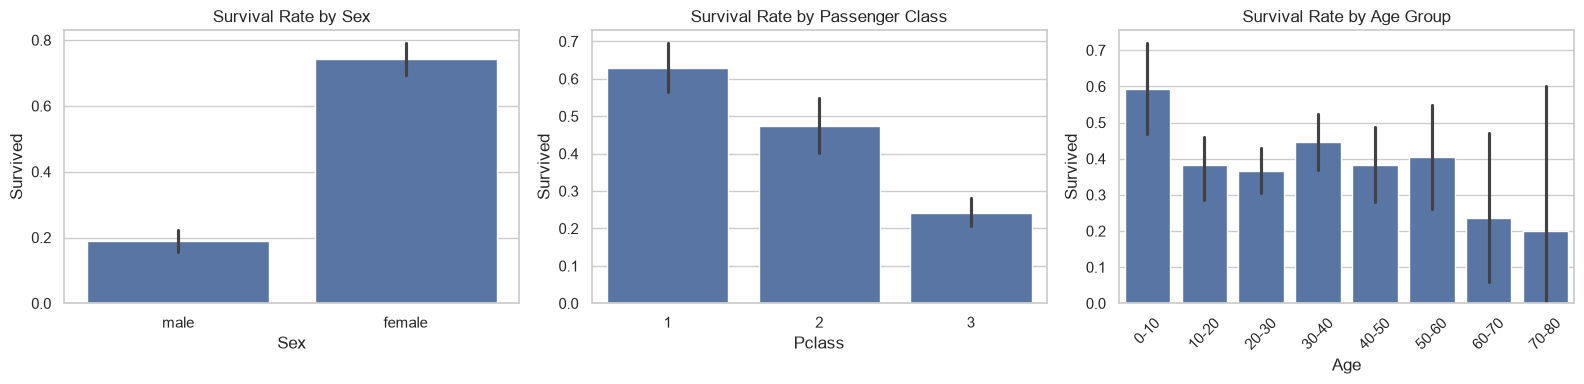

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(x="Sex", y="Survived", data=titanic, ax=axes[0])
axes[0].set_title("Survival Rate by Sex")

sns.barplot(x="Pclass", y="Survived", data=titanic, ax=axes[1])
axes[1].set_title("Survival Rate by Passenger Class")

bins = [0, 10, 20, 30, 40, 50, 60, 70, 80]
labels = ["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60-70", "70-80"]
age_binned = pd.cut(titanic["Age"], bins=bins, labels=labels)
sns.barplot(x=age_binned, y="Survived", data=titanic, ax=axes[2])
axes[2].set_title("Survival Rate by Age Group")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 3. Feature Engineering & Train/Test Split

- Extract `Title` from `Name` using a raw regex string and consolidate rare titles into `'Other'` to avoid sparse noisy categories.
- Create `AgeGroup` with explicit ordered categories.
- Drop non-predictive identifiers/high-cardinality text columns (`PassengerId`, `Name`, `Ticket`, `Cabin`).
- Perform a stratified `80/20` train/test split **before** fitting any imputers, encoders, or scalers.

In [ ]:
df = titanic.copy()

# Extract and group passenger titles
df["Title"] = (
    df["Name"]
    .str.extract(r",\s*([A-Za-z]+)\.", expand=False)
    .fillna("Unknown")
)
common_titles = {"Mr", "Miss", "Mrs", "Master"}
df["Title"] = df["Title"].where(df["Title"].isin(common_titles), "Other")

# Create ordered age bins (keep NaN intact so SimpleImputer handles missing values inside CV)
bins = [0, 10, 20, 30, 40, 50, 60, 70, 80]
labels = ["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60-70", "70-80"]
df["AgeGroup"] = pd.cut(df["Age"], bins=bins, labels=labels).astype("object")


# Separate features and target
drop_cols = ["Survived", "PassengerId", "Name", "Ticket", "Cabin"]
X = df.drop(columns=drop_cols)
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")

X_train shape: (712, 9) | X_test shape: (179, 9)


## 4. Leakage-Free Preprocessing Pipeline

- **Numerical features (`Age`, `Fare`, `SibSp`, `Parch`):** Median imputation + `StandardScaler`.
- **Ordinal features (`AgeGroup`):** Most-frequent imputation + `OrdinalEncoder` preserving age order.
- **Nominal features (`Sex`, `Embarked`, `Title`, `Pclass`):** Most-frequent imputation + `OneHotEncoder` (avoids artificial integer ordering on nominal categories).

In [32]:
num_cols = ["Age", "Fare", "SibSp", "Parch"]
ordinal_cols = ["AgeGroup"]
nominal_cols = ["Sex", "Embarked", "Title", "Pclass"]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

ordinal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "ordinal",
        OrdinalEncoder(
            categories=[labels],
            handle_unknown="use_encoded_value",
            unknown_value=-1,
        ),
    ),
])

nominal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("ord", ordinal_pipe, ordinal_cols),
    ("nom", nominal_pipe, nominal_cols),
])

## 5. Model Comparison with Stratified 5-Fold Cross-Validation

In [33]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
}

scoring = ["accuracy", "precision", "recall", "f1"]
cv_results = []

for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
    })

results_df = pd.DataFrame(cv_results).sort_values(by="F1", ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1
0,LogisticRegression,0.820250,0.785200,0.736364,0.758568
2,XGBoost,0.804806,0.749515,0.740000,0.744046
1,RandomForest,0.800581,0.745559,0.728956,0.736733


## 6. Hyperparameter Tuning (GridSearchCV Inside Pipeline)

In [34]:
# Tune Logistic Regression regularization
lr_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
lr_grid = GridSearchCV(
    lr_pipe,
    param_grid={"model__C": [0.01, 0.1, 1, 10, 100]},
    cv=cv,
    scoring="f1",
).fit(X_train, y_train)

print(f"Best LR Params: {lr_grid.best_params_} | Best CV F1: {lr_grid.best_score_:.4f}")

# Tune Random Forest depth & split constraints to control overfitting
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(random_state=42)),
])
rf_grid = GridSearchCV(
    rf_pipe,
    param_grid={
        "model__n_estimators": [100, 200],
        "model__max_depth": [4, 6, 8, None],
        "model__min_samples_split": [2, 5, 10],
    },
    cv=cv,
    scoring="f1",
    n_jobs=-1,
).fit(X_train, y_train)

print(f"Best RF Params: {rf_grid.best_params_} | Best CV F1: {rf_grid.best_score_:.4f}")

Best LR Params: {'model__C': 10} | Best CV F1: 0.7610
Best RF Params: {'model__max_depth': 4, 'model__min_samples_split': 2, 'model__n_estimators': 100} | Best CV F1: 0.7621


## 7. Final Evaluation on Held-Out Test Set

Selected Model: RandomForestClassifier(max_depth=4, random_state=42)

Test Set Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86       110
           1       0.81      0.70      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



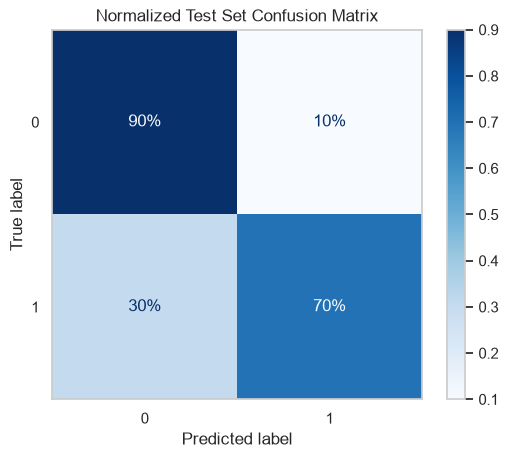

In [35]:
# Select the top cross-validated estimator
best_model = rf_grid.best_estimator_ if rf_grid.best_score_ >= lr_grid.best_score_ else lr_grid.best_estimator_
print("Selected Model:", best_model.named_steps["model"])

y_pred = best_model.predict(X_test)
print("\nTest Set Classification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, normalize="true", cmap="Blues", values_format=".0%"
)
plt.title("Normalized Test Set Confusion Matrix")
plt.grid(False)
plt.show()